In [1]:
from importlib import reload
import plotting_utils as pu

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

cell_types = ["Exc", "Pvalb", "Sst", "Vip", "Htr3a"]
colors = [
    "tab:red",
    "tab:blue",
    "tab:green",
    "tab:purple",
    "tab:purple",
]
layers = ["L1", "L2/3", "L4", "L5", "L6"]

layer_cell = []
for layer in ["L1", "L2/3", "L4", "L5", "L6"]:
    for cell_type in ["Exc", "Pvalb", "Sst", "Vip", "Htr3a"]:
        if (layer == "L1") & (cell_type != "Htr3a"):
            continue
        if (layer != "L1") & (cell_type == "Htr3a"):
            continue
        layer_cell.append(layer + " " + cell_type)

## Fig 5 suppl: firing rates distribution

In [2]:
# Each entry: condition label -> absolute path to config_0.json
# Isolated L4 configs (L1, L2/3, L5, L6 silenced)
L4_ISOLATED_SUFFIX = "/configs/8dir_10trials_opto_layer_silencing_L1_L23_L5_L6_-2000_checkpoint/config_0.json"

Perturb_dict_L4 = {
    # Fig 5A group 1: cell/connectivity perturbations
    "L4 - no perturb":                      "core" + L4_ISOLATED_SUFFIX,
    "L4 with L6 cell vol dens & conn":      "core_L4-cell-vol-dens-conn-as-L6" + L4_ISOLATED_SUFFIX,
    "L4 with L6 cell models":                "core/configs/8dir_10trials_L4_with_L6_models_opto_layer_silencing_L1_L23_L5_L6_-2000_checkpoint/config_0.json",
    # Fig 5A group 2: all syn params
    "L4 with L6 syn params":                 "core_L4-syn-as-L6-syn" + L4_ISOLATED_SUFFIX,
    "L4 with L6 I-to-E syn params":          "core_L4-i2e-syn-as-L6" + L4_ISOLATED_SUFFIX,
    # Fig 5A group 3: inhibitory cell-type synaptic
    "L4 with L6 Pvalb-to-E syn params":      "core_L4-Pvalb2e-as-L6" + L4_ISOLATED_SUFFIX,
    "L4 with L6 Pvalb-to-E latency":         "core_L4-Pvalb2e-syn-lat-as-L6" + L4_ISOLATED_SUFFIX,
    "L4 with L6 Pvalb-to-E tau amp":         "core_L4-Pvalb2e-syn-tau-amp-as-L6" + L4_ISOLATED_SUFFIX,
    "L4 with L6 Sst-to-E syn params":        "core_L4-Sst2e-as-L6" + L4_ISOLATED_SUFFIX,
    # Fig 5A suppl group 1: cell density / connectivity
    "L4 with L6 cell vol dens":              "core_L4-cell-volume-density-as-L6" + L4_ISOLATED_SUFFIX,
    "L4 with L6 connectivity":               "core_L4-connectivity-as-L6" + L4_ISOLATED_SUFFIX,
    # Fig 5A suppl group 2: excitatory synaptic
    "L4 with L6 E-to-E syn params":          "core_L4-e2e-syn-as-L6" + L4_ISOLATED_SUFFIX,
    "L4 with L6 E-to-I syn params":          "core_L4-e2i-syn-as-L6" + L4_ISOLATED_SUFFIX,
    # Fig 5A suppl group 3: Sst/Vip synaptic
    "L4 with L6 Sst-to-E latency":          "core_L4-Sst2e-syn-lat-as-L6" + L4_ISOLATED_SUFFIX,
    "L4 with L6 Sst-to-E tau amp":          "core_L4-Sst2e-syn-tau-amp-as-L6" + L4_ISOLATED_SUFFIX,
    "L4 with L6 Vip-to-E tau amp":          "core_L4-Vip2e-syn-tau-amp-as-L6" + L4_ISOLATED_SUFFIX,
    # Fig 5A suppl group 4: inhibitory cell model swaps
    "L4 Sst with L4 Pvalb models & syn":      "core_i4Sst-like-i4Pvalb" + L4_ISOLATED_SUFFIX,
    "L4 Pvalb with L4 Sst models & syn":      "core_i4Pvalb-like-i4Sst" + L4_ISOLATED_SUFFIX,
}

# Isolated L6 configs (L1, L2/3, L4, L5 silenced)
L6_ISOLATED_SUFFIX = "/configs/8dir_10trials_opto_layer_silencing_L1_L23_L4_L5_-2000_checkpoint/config_0.json"

Perturb_dict_L6 = {
    "L6 - no perturb":                     "core" + L6_ISOLATED_SUFFIX,
    "L6 with L4 syn params":               "core_L6-syn-as-L4-syn" + L6_ISOLATED_SUFFIX,
    # "L6 with L4 syn + 20x lgn2L6":        "core_L6-syn-as-L4-syn/configs/8dir_10trials_perturb_syn_lgn2L6_factor_20_opto_layer_silencing_L1_L23_L4_L5_-2000_checkpoint/config_0.json",
    "L6 with L4 cell models,\ncell vol dens, conn & syn":
                                            "core_L6-as-L4/configs/8dir_10trials_L6_with_L4_models_opto_layer_silencing_L1_L23_L4_L5_-2000_checkpoint/config_0.json",
}


In [3]:
def load_condition(condition, config_path):
    v1df, _ = pu.data_organize(
        config_path, t_min=500, t_max=3000, radius=pu.settings["core"]["radius"]
    )
    v1df["condition"] = condition
    return v1df

v1df_L4 = pd.DataFrame()
for condition, config_path in Perturb_dict_L4.items():
    print(condition)
    v1df_L4 = pd.concat([v1df_L4, load_condition(condition, config_path)])

v1df_L4["cell_layer"] = v1df_L4.apply(
    lambda row: row["layer"] + " " + row["cell_type"], axis=1
)

v1df_L6 = pd.DataFrame()
for condition, config_path in Perturb_dict_L6.items():
    print(condition)
    v1df_L6 = pd.concat([v1df_L6, load_condition(condition, config_path)])

v1df_L6["cell_layer"] = v1df_L6.apply(
    lambda row: row["layer"] + " " + row["cell_type"], axis=1
)


L4 - no perturb
inferring network from core


L4 with L6 cell vol dens & conn
inferring network from core_L4-cell-vol-dens-conn-as-L6


L4 with L6 cell models
inferring network from core


L4 with L6 syn params
inferring network from core_L4-syn-as-L6-syn


L4 with L6 I-to-E syn params
inferring network from core_L4-i2e-syn-as-L6


L4 with L6 Pvalb-to-E syn params
inferring network from core_L4-Pvalb2e-as-L6


... (11 outputs left out)

L4 Pvalb with L4 Sst models & syn
inferring network from core_i4Pvalb-like-i4Sst


L6 - no perturb
inferring network from core


L6 with L4 syn params
inferring network from core_L6-syn-as-L4-syn


L6 with L4 cell models,
cell vol dens, conn & syn
inferring network from core_L6-as-L4


/tmp/ipykernel_3702436/1881088290.py:106: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=xlabel_rotation, ha=ha)
/tmp/ipykernel_3702436/1881088290.py:106: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=xlabel_rotation, ha=ha)


/tmp/ipykernel_3702436/1881088290.py:106: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=xlabel_rotation, ha=ha)
/tmp/ipykernel_3702436/1881088290.py:106: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=xlabel_rotation, ha=ha)


/tmp/ipykernel_3702436/1881088290.py:106: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=xlabel_rotation, ha=ha)


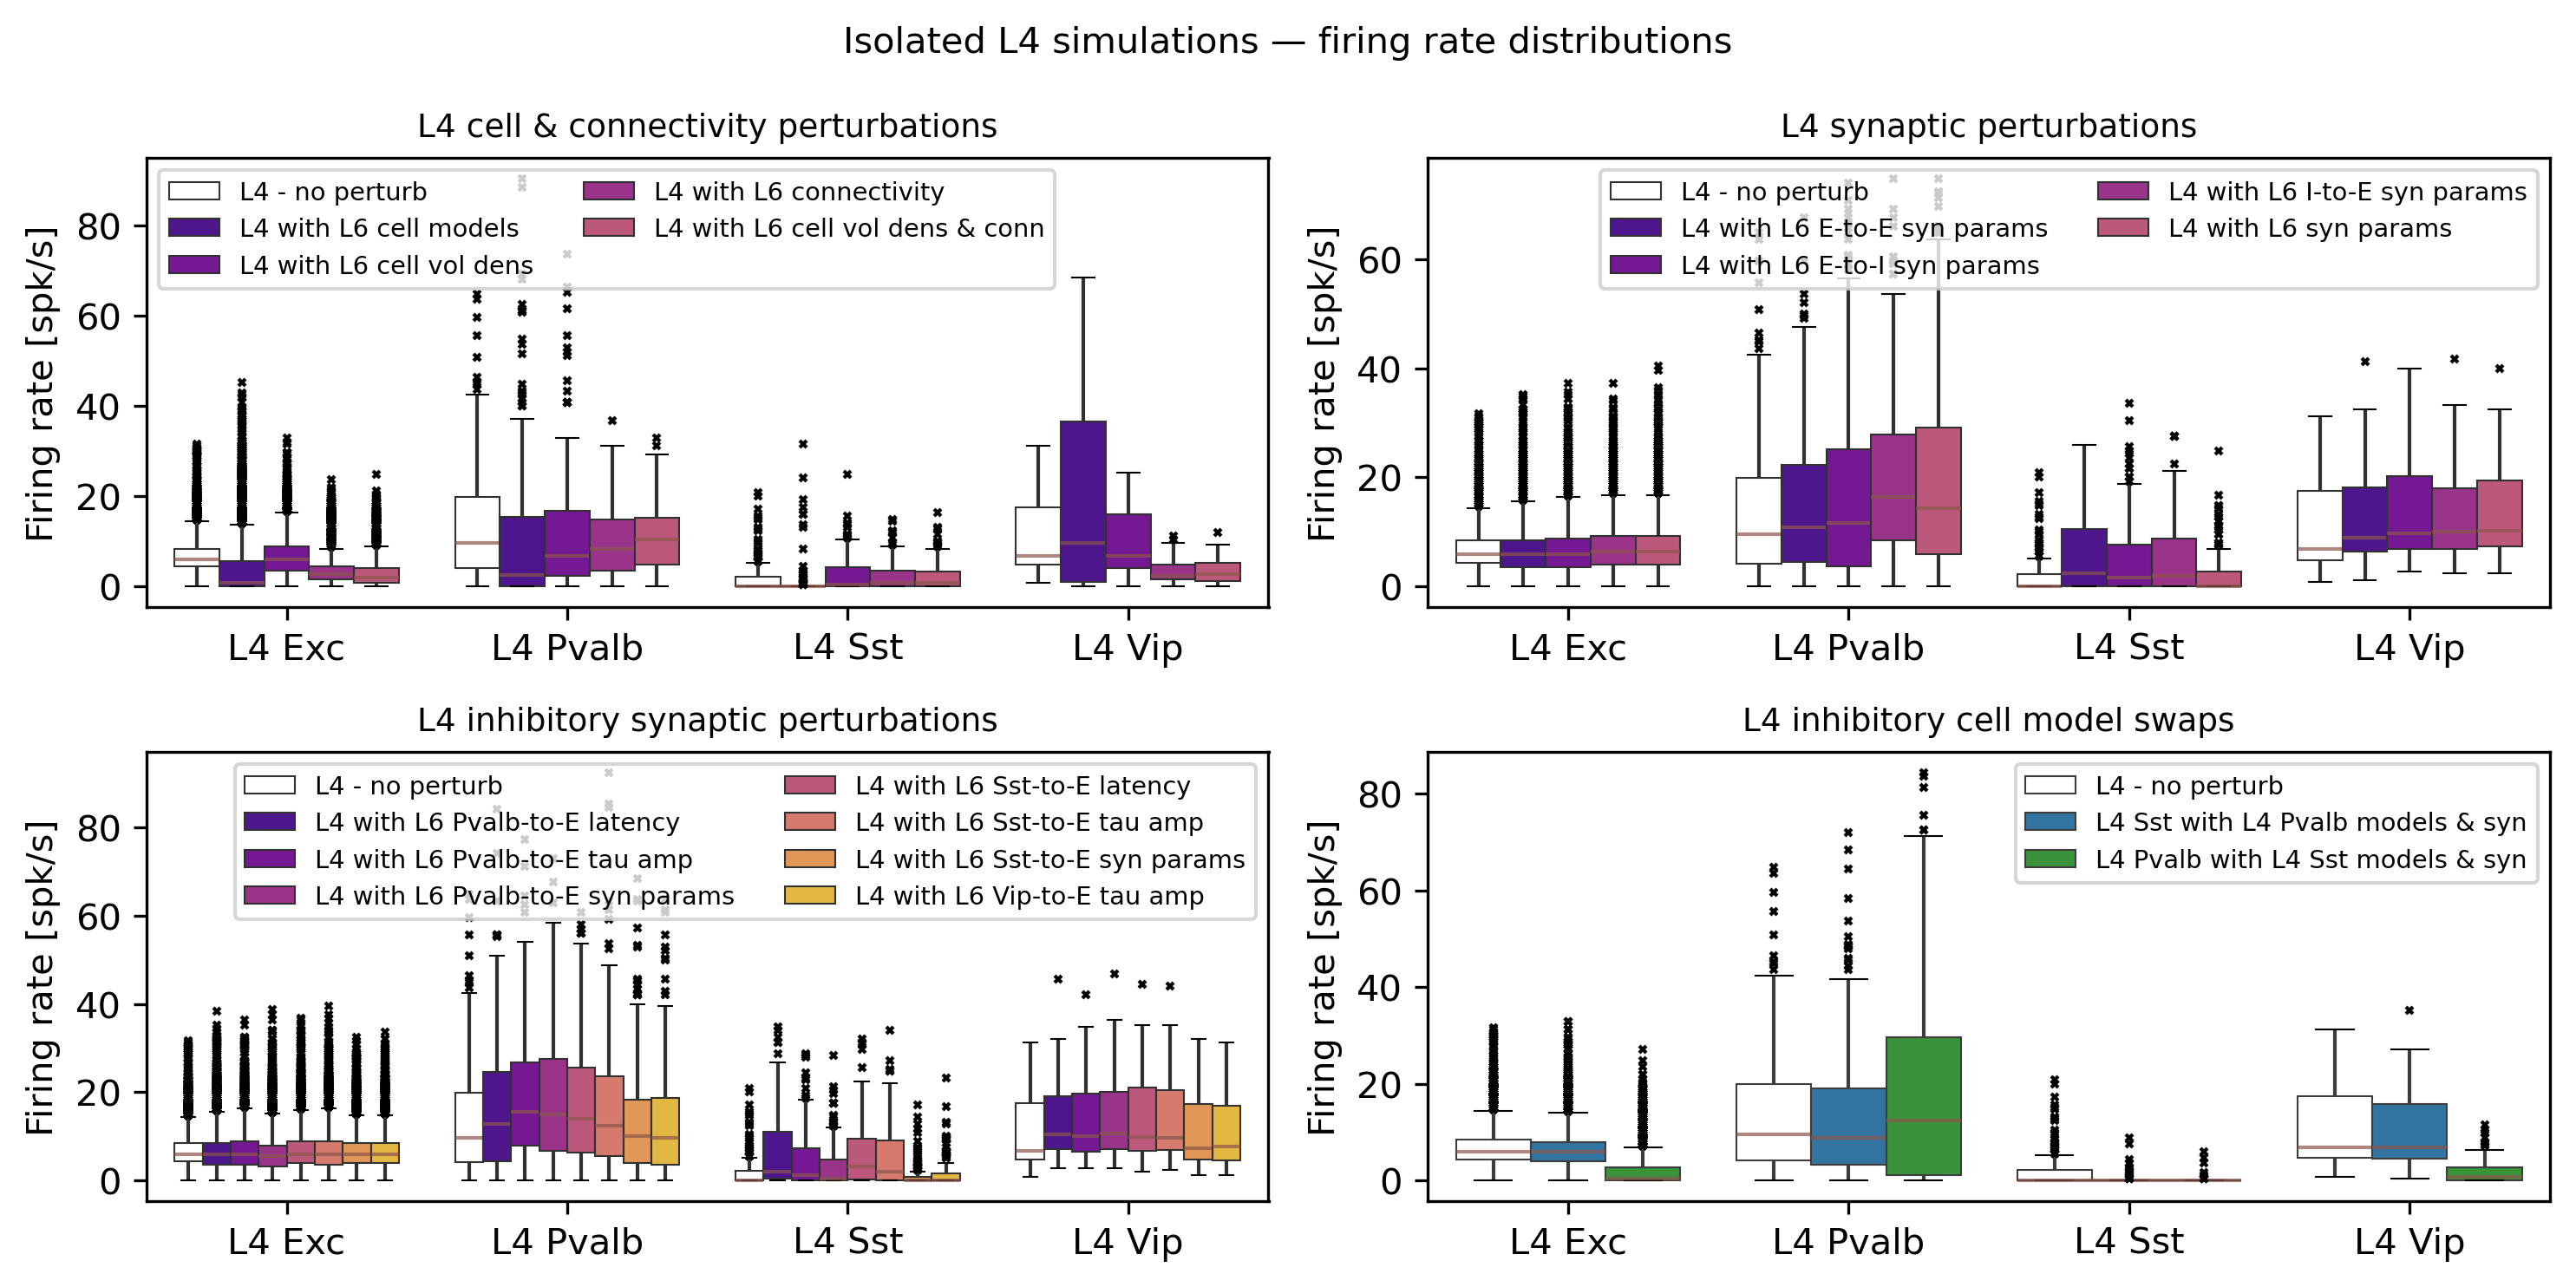

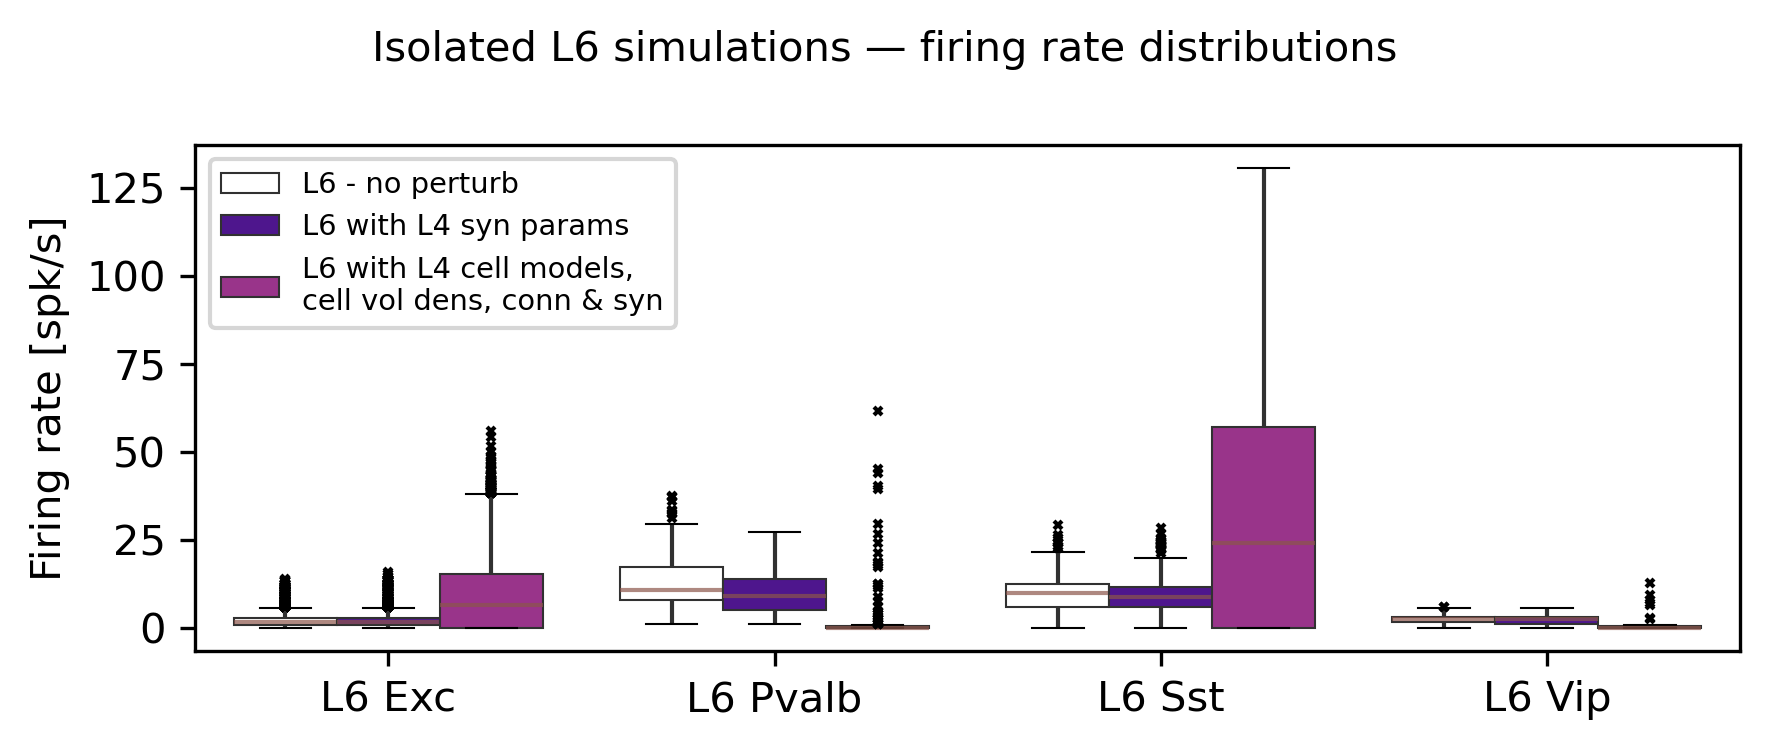

In [4]:
colors = np.delete(plt.colormaps["plasma"](np.linspace(0, 1, 9)), 8, axis=0)
swap_colors = ["tab:blue", "tab:green"]

# ─── Merged row conditions & palettes ────────────────────────────────────────

# Row 1: cell/connectivity — "cell vol dens & conn" last
conds_R1 = [
    "L4 - no perturb",
    "L4 with L6 cell models",
    "L4 with L6 cell vol dens",
    "L4 with L6 connectivity",
    "L4 with L6 cell vol dens & conn",
]
pal_R1 = {
    "L4 - no perturb":                  "white",
    "L4 with L6 cell models":           colors[1],
    "L4 with L6 cell vol dens":         colors[2],
    "L4 with L6 connectivity":          colors[3],
    "L4 with L6 cell vol dens & conn": colors[4],
}

# Row 2: synaptic — order: E-to-E, E-to-I, I-to-E, all syn
conds_R2 = [
    "L4 - no perturb",
    "L4 with L6 E-to-E syn params",
    "L4 with L6 E-to-I syn params",
    "L4 with L6 I-to-E syn params",
    "L4 with L6 syn params",
]
pal_R2 = {
    "L4 - no perturb":               "white",
    "L4 with L6 E-to-E syn params":  colors[1],
    "L4 with L6 E-to-I syn params":  colors[2],
    "L4 with L6 I-to-E syn params":  colors[3],
    "L4 with L6 syn params":         colors[4],
}

# Row 3: inhibitory synaptic — order: latency, tau amp, syn params; Pvalb → Sst → Vip
conds_R3 = [
    "L4 - no perturb",
    "L4 with L6 Pvalb-to-E latency",
    "L4 with L6 Pvalb-to-E tau amp",
    "L4 with L6 Pvalb-to-E syn params",
    "L4 with L6 Sst-to-E latency",
    "L4 with L6 Sst-to-E tau amp",
    "L4 with L6 Sst-to-E syn params",
    "L4 with L6 Vip-to-E tau amp",
]
pal_R3 = {
    "L4 - no perturb":                   "white",
    "L4 with L6 Pvalb-to-E latency":     colors[1],
    "L4 with L6 Pvalb-to-E tau amp":     colors[2],
    "L4 with L6 Pvalb-to-E syn params":  colors[3],
    "L4 with L6 Sst-to-E latency":       colors[4],
    "L4 with L6 Sst-to-E tau amp":       colors[5],
    "L4 with L6 Sst-to-E syn params":    colors[6],
    "L4 with L6 Vip-to-E tau amp":       colors[7],
}

# Row 4: inhibitory cell model swaps
conds_R4 = [
    "L4 - no perturb",
    "L4 Sst with L4 Pvalb models & syn",
    "L4 Pvalb with L4 Sst models & syn",
]
pal_R4 = {
    "L4 - no perturb":                 "white",
    "L4 Sst with L4 Pvalb models & syn": swap_colors[0],
    "L4 Pvalb with L4 Sst models & syn": swap_colors[1],
}

# Fig 5B – L6 perturbations
conds_L6 = list(Perturb_dict_L6.keys())
pal_L6 = {
    "L6 - no perturb":                                    "white",
    "L6 with L4 syn params":                              colors[1],
    # "L6 with L4 syn + 20x lgn2L6":                       colors[2],
    "L6 with L4 cell models,\ncell vol dens, conn & syn": colors[3],
}

# ─── helper ──────────────────────────────────────────────────────────────────

def make_boxplot(ax, v1df, conditions, palette, layer_filter, legend_ncol=1, xlabel_rotation=45):
    sub_df = v1df[v1df["condition"].isin(conditions)].copy()
    if layer_filter is not None:
        sub_df = sub_df[sub_df["layer"].isin(layer_filter)]
        order_to_use = [lc for lc in layer_cell if any(lc.startswith(l + " ") for l in layer_filter)]
    else:
        order_to_use = layer_cell
    sns.boxplot(
        ax=ax,
        data=sub_df,
        x="cell_layer",
        y="fr_stimulus",
        hue="condition",
        hue_order=conditions,
        palette=palette,
        flierprops=dict(marker="x", markeredgecolor="black", markersize=2, zorder=2),
        medianprops=dict(color="tab:brown", alpha=0.7, zorder=2),
        boxprops=dict(linewidth=0.5, zorder=2),
        capprops=dict(color="black", linewidth=0.5, zorder=2),
        order=order_to_use,
    )
    ax.legend(fontsize="x-small", ncol=legend_ncol)
    ha = "right" if xlabel_rotation != 0 else "center"
    ax.set_xticklabels(ax.get_xticklabels(), rotation=xlabel_rotation, ha=ha)
    ax.set_xlabel(None)
    ax.set_ylabel("Firing rate [spk/s]")

# ─── Figure 1: merged L4 perturbations (2×2 grid) ────────────────────────────
fig1, axes1 = plt.subplots(2, 2, figsize=(10, 5), dpi=300)
fig1.patch.set_facecolor("none")

specs_fig1 = [
    ("L4 cell & connectivity perturbations",  conds_R1, pal_R1, 2),
    ("L4 synaptic perturbations",             conds_R2, pal_R2, 2),
    ("L4 inhibitory synaptic perturbations",  conds_R3, pal_R3, 2),
    ("L4 inhibitory cell model swaps",        conds_R4, pal_R4, 1),
]
for ax, (title, conds, pal, ncol) in zip(axes1.flatten(), specs_fig1):
    ax.set_title(title, fontsize=9)
    make_boxplot(ax, v1df_L4, conds, pal, layer_filter=["L4"], legend_ncol=ncol, xlabel_rotation=0)

fig1.suptitle("Isolated L4 simulations — firing rate distributions", fontsize=10)
fig1.tight_layout()
fig1.savefig(
    "paper_figs/fig5_suppl_dg_firing_rate_dist_L4_pertb_June16_2026.pdf",
    dpi=300, bbox_inches="tight", transparent=True,
)

# ─── Figure 2: Isolated L6 – matches Fig 5B ──────────────────────────────────
fig2, ax2 = plt.subplots(1, 1, figsize=(6, 2.5), dpi=300)
fig2.patch.set_facecolor("none")
make_boxplot(ax2, v1df_L6, conds_L6, pal_L6, layer_filter=["L6"], legend_ncol=1, xlabel_rotation=0)
fig2.suptitle("Isolated L6 simulations — firing rate distributions", fontsize=10)
fig2.tight_layout()
fig2.savefig(
    "paper_figs/fig5_suppl_dg_firing_rate_dist_L6_pertb_July17_2026.pdf",
    dpi=300, bbox_inches="tight", transparent=True,
)
